# 2026 — The Modern LLM Recipe

The 2017 Transformer block has been refined piece by piece. By 2025–2026 the open frontier models (Llama 3/4, Qwen3, DeepSeek-V3, Gemma 3, OLMo 2/3, Kimi K2, gpt-oss, ...) agree on a fairly standard **dense block**, often combined with MoE (notebook 32), MLA (34) or hybrid linear attention (36):

| component | replaces | origin |
|---|---|---|
| **Pre-norm + RMSNorm** | post-LayerNorm | Zhang & Sennrich 2019 |
| **RoPE** rotary positions | learned/sinusoidal absolute | Su et al. 2021 |
| **GQA** grouped-query attention | full multi-head KV | Ainslie et al. 2023 |
| **QK-Norm** | — (stabilises logits at scale) | Dehghani et al. 2023; OLMo 2, Qwen3, Gemma 3 |
| **SwiGLU** feed-forward | GELU MLP | Shazeer 2020 |
| no biases, tied/untied embeddings, z-loss | — | PaLM 2022 and others |
| **FlashAttention** kernels | naive attention | Dao et al. 2022–2024 |
| **Muon** optimizer for hidden matrices | AdamW everywhere | Jordan et al. 2024; Kimi K2 (2025) |

This notebook builds that block from scratch, trains it next to the GPT-2-style block from 2018 on the same data, and compares AdamW with **Muon**, an optimizer that orthogonalises each weight-matrix update with a Newton–Schulz iteration.

Data: a procedurally generated corpus (~200K characters) so that there is a real held-out validation set.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
rng = random.Random(0)
subjects = ["the model", "a small network", "the optimizer", "each layer", "the attention head", "the router", "a student", "the teacher"]
verbs = ["learns", "predicts", "updates", "compresses", "routes", "remembers", "forgets", "copies"]
objects = ["the next token", "a hidden state", "the gradient", "its weights", "a long context", "the key and value", "every expert", "the loss"]
advs = ["quickly", "slowly", "carefully", "in parallel", "step by step", "without labels", "at scale", "once again"]
def sentence():
    s = f"{rng.choice(subjects)} {rng.choice(verbs)} {rng.choice(objects)} {rng.choice(advs)}"
    if rng.random() < 0.4: s += f" because {rng.choice(subjects)} {rng.choice(verbs)} {rng.choice(objects)}"
    if rng.random() < 0.2: s += f", then {rng.choice(subjects)} {rng.choice(verbs)} {rng.choice(objects)}"
    return s[0].upper() + s[1:] + ". "
text = "".join(sentence() for _ in range(4000))
chars = sorted(set(text)); V = len(chars); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], device=device)
split = int(0.9 * len(data)); train_data, val_data = data[:split], data[split:]
print(f"{len(text):,} characters, vocab {V}\n", text[:200])

290,321 characters, vocab 31
 A student forgets the next token step by step. The attention head copies the key and value in parallel. A small network routes the gradient step by step because a small network remembers the loss. The


## The modern block

In [3]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6): super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x): return self.w * x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)

def rope(x, base=10000.0):
    """Rotary embedding on (B, h, T, d): rotate pairs of channels by a position-dependent angle."""
    T, d = x.shape[-2], x.shape[-1]
    inv = 1.0 / base ** (torch.arange(0, d, 2, device=x.device).float() / d)
    ang = torch.arange(T, device=x.device).float()[:, None] * inv
    cos, sin = ang.cos(), ang.sin()
    x1, x2 = x[..., ::2], x[..., 1::2]
    return torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], -1).flatten(-2)

class GQAttention(nn.Module):
    def __init__(self, d, n_heads=4, n_kv_heads=2, qk_norm=True):
        super().__init__()
        self.h, self.kvh, self.dh = n_heads, n_kv_heads, d // n_heads
        self.wq = nn.Linear(d, n_heads * self.dh, bias=False)
        self.wkv = nn.Linear(d, 2 * n_kv_heads * self.dh, bias=False)        # fewer K/V heads -> smaller KV cache
        self.wo = nn.Linear(n_heads * self.dh, d, bias=False)
        self.qn, self.kn = (RMSNorm(self.dh), RMSNorm(self.dh)) if qk_norm else (nn.Identity(), nn.Identity())
    def forward(self, x):
        B, T, _ = x.shape
        q = self.wq(x).view(B, T, self.h, self.dh).transpose(1, 2)
        k, v = self.wkv(x).view(B, T, 2, self.kvh, self.dh).permute(2, 0, 3, 1, 4)
        q, k = rope(self.qn(q)), rope(self.kn(k))                              # QK-norm, then RoPE
        k, v = k.repeat_interleave(self.h // self.kvh, 1), v.repeat_interleave(self.h // self.kvh, 1)
        o = F.scaled_dot_product_attention(q, k, v, is_causal=True)            # fused / Flash kernel when available
        return self.wo(o.transpose(1, 2).reshape(B, T, -1))

class SwiGLU(nn.Module):
    def __init__(self, d, hidden):
        super().__init__()
        self.w_gate, self.w_up, self.w_down = (nn.Linear(d, hidden, bias=False), nn.Linear(d, hidden, bias=False), nn.Linear(hidden, d, bias=False))
    def forward(self, x): return self.w_down(F.silu(self.w_gate(x)) * self.w_up(x))

class ModernBlock(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.n1, self.n2 = RMSNorm(d), RMSNorm(d)
        self.attn, self.mlp = GQAttention(d), SwiGLU(d, int(8 * d / 3))          # 8/3·d keeps params ≈ a 4·d GELU MLP
    def forward(self, x):
        x = x + self.attn(self.n1(x))
        return x + self.mlp(self.n2(x))

class GPT2Block(nn.Module):                                                     # the 2018/2019 baseline
    def __init__(self, d, ctx=128):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj, self.h = nn.Linear(d, 3 * d), nn.Linear(d, d), 4
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(self.n1(x)).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        x = x + self.proj(F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B, T, D))
        return x + self.mlp(self.n2(x))

class LM(nn.Module):
    def __init__(self, block, d=128, n=4, ctx=128):
        super().__init__()
        self.modern = block is ModernBlock
        self.tok = nn.Embedding(V, d)
        self.pos = None if self.modern else nn.Embedding(ctx, d)                   # RoPE needs no position table
        self.blocks = nn.ModuleList([block(d) for _ in range(n)])
        self.norm = RMSNorm(d) if self.modern else nn.LayerNorm(d)
        self.head = nn.Linear(d, V, bias=False)
        self.apply(lambda m: nn.init.normal_(m.weight, std=0.02) if isinstance(m, (nn.Linear, nn.Embedding)) else None)
    def forward(self, idx):
        x = self.tok(idx)
        if self.pos is not None: x = x + self.pos(torch.arange(idx.shape[1], device=idx.device))
        for b in self.blocks: x = b(x)
        return self.head(self.norm(x))

## Muon: orthogonalised momentum for weight matrices
For each 2-D hidden weight, take the momentum $M$ and replace it with the nearest semi-orthogonal matrix $\approx UV^\top$ (from $M = U\Sigma V^\top$), computed with 5 Newton–Schulz iterations instead of an SVD. Every direction then gets an equal-sized update. Embeddings, the output head and norm gains stay on AdamW.

In [4]:
def newton_schulz(G, steps=5):
    a, b, c = 3.4445, -4.7750, 2.0315                       # coefficients from Keller Jordan's Muon
    X = G / (G.norm() + 1e-7)
    transposed = X.shape[0] > X.shape[1]
    if transposed: X = X.T
    for _ in range(steps):
        A = X @ X.T
        X = a * X + (b * A + c * A @ A) @ X
    return X.T if transposed else X

class Muon(torch.optim.Optimizer):
    def __init__(self, params, lr=0.02, momentum=0.95):
        super().__init__(params, dict(lr=lr, momentum=momentum))
    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            for p in g["params"]:
                if p.grad is None: continue
                buf = self.state[p].setdefault("buf", torch.zeros_like(p))
                buf.mul_(g["momentum"]).add_(p.grad)
                update = newton_schulz(p.grad + g["momentum"] * buf)                 # Nesterov-style
                p.add_(update, alpha=-g["lr"] * max(1, p.shape[0] / p.shape[1]) ** 0.5)

G = torch.randn(64, 32)
S = torch.linalg.svdvals(newton_schulz(G))
print(f"singular values after Newton–Schulz: min {S.min():.2f}, max {S.max():.2f}  (raw gradient: {torch.linalg.svdvals(G).min():.1f}…{torch.linalg.svdvals(G).max():.1f})")

singular values after Newton–Schulz: min 0.68, max 1.04  (raw gradient: 2.7…13.4)


## Train and compare
A short run (400 steps), so that differences in *speed of learning* are visible before every model reaches the floor set by the randomness of the grammar. Be careful reading toy results: at this scale the gaps are small and can change with the seed or learning rate. The modern components matter most for **stability and efficiency at scale** (billions of parameters, long contexts, low precision), which a notebook cannot reproduce.

In [5]:
ctx, B, steps = 128, 32, 400
def get_batch(src):
    ix = torch.randint(0, len(src) - ctx - 1, (B,), device=device)
    return torch.stack([src[i:i + ctx] for i in ix]), torch.stack([src[i + 1:i + ctx + 1] for i in ix])

@torch.no_grad()
def val_loss(m):
    m.eval(); l = np.mean([F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1)).item() for x, y in (get_batch(val_data) for _ in range(10))]); m.train(); return l

def run(block, optim):
    seed_everything(0)
    m = LM(block).to(device)
    if optim == "muon":
        hidden = [p for n, p in m.named_parameters() if p.ndim == 2 and "blocks" in n]
        rest = [p for n, p in m.named_parameters() if not (p.ndim == 2 and "blocks" in n)]
        opts = [Muon(hidden, lr=0.02), torch.optim.AdamW(rest, lr=3e-3, betas=(0.9, 0.95), weight_decay=0.0)]
    else:
        opts = [torch.optim.AdamW(m.parameters(), lr=3e-3, betas=(0.9, 0.95), weight_decay=0.1)]
    base_lrs = [[g["lr"] for g in o.param_groups] for o in opts]
    curve, t0 = [], time.time()
    for s in range(steps):
        frac = min(1, (s + 1) / 50) * 0.5 * (1 + math.cos(math.pi * s / steps))      # warmup + cosine decay
        for o, lrs in zip(opts, base_lrs):
            for g, lr in zip(o.param_groups, lrs): g["lr"] = lr * frac
        x, y = get_batch(train_data)
        loss = F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1))
        for o in opts: o.zero_grad()
        loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        for o in opts: o.step()
        if s % 50 == 0 or s == steps - 1: curve.append((s, val_loss(m)))
    n_params = sum(p.numel() for p in m.parameters())
    print(f"{block.__name__:11s} + {optim:5s}: params {n_params / 1e3:.0f}K | final val loss {curve[-1][1]:.4f} | {time.time() - t0:.0f}s")
    return m, curve

runs = {name: run(blk, opt) for name, blk, opt in [("GPT-2 block + AdamW", GPT2Block, "adamw"),
                                                     ("modern block + AdamW", ModernBlock, "adamw"),
                                                     ("modern block + Muon", ModernBlock, "muon")]}

GPT2Block   + adamw: params 818K | final val loss 0.2181 | 51s


ModernBlock + adamw: params 730K | final val loss 0.2105 | 66s


ModernBlock + muon : params 730K | final val loss 0.2101 | 72s


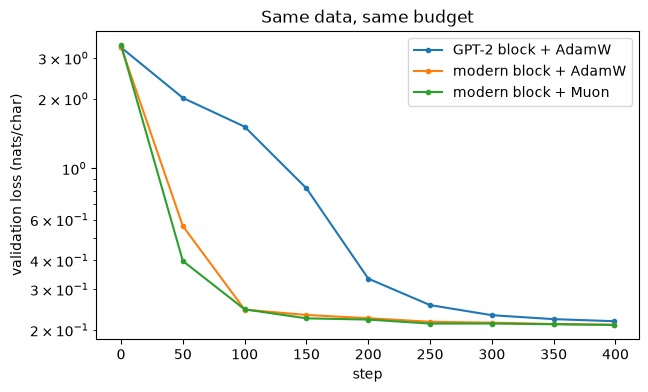

step     GPT-2 block + AdamW    modern block + AdamW     modern block + Muon
   0                  3.3299                  3.3546                  3.4134
  50                  2.0151                  0.5626                  0.3973
 100                  1.5123                  0.2447                  0.2454
 150                  0.8190                  0.2321                  0.2244
 200                  0.3332                  0.2247                  0.2217
 250                  0.2561                  0.2169                  0.2130
 300                  0.2316                  0.2149                  0.2131
 350                  0.2227                  0.2121                  0.2117
 399                  0.2181                  0.2105                  0.2101


In [6]:
plt.figure(figsize=(7, 4))
for name, (_, c) in runs.items(): plt.plot(*zip(*c), marker=".", label=name)
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("validation loss (nats/char)"); plt.legend(); plt.title("Same data, same budget"); plt.show()
print("step  " + "  ".join(f"{n:>22s}" for n in runs))
for i, (s, _) in enumerate(next(iter(runs.values()))[1]):
    print(f"{s:4d}  " + "  ".join(f"{c[i][1]:22.4f}" for _, c in runs.values()))

In [7]:
m = runs["modern block + Muon"][0].eval()
idx = torch.tensor([[stoi[c] for c in "The model "]], device=device)
with torch.no_grad():
    for _ in range(200):
        idx = torch.cat([idx, torch.multinomial((m(idx[:, -ctx:])[:, -1] / 0.8).softmax(-1), 1)], 1)
print("".join(chars[i] for i in idx[0].tolist()))

The model copies the next token in parallel, then each layer predicts the next token. The model forgets the key and value step by step. The router remembers the loss without labels because the optimizer routes 


## Where this leaves us (late 2026)
- **Dense block:** RMSNorm + RoPE + GQA/MLA + QK-norm + SwiGLU, in pre-norm residual form. Every piece is in this repo.
- **Sparsity:** fine-grained MoE with shared experts (notebook 32).
- **Long context:** learned sparse attention and hybrid local/global stacks (notebook 39), linear-memory layers (Gated DeltaNet, notebook 36) and compressed KV caches (MLA, notebook 34).
- **Post-training:** SFT, then RL with verifiable rewards (GRPO family, notebook 35) to train reasoning.
- **Generation beyond text:** diffusion / flow matching (27, 30) with Transformer backbones.
- And still at the core: the weighted sum + nonlinearity of 1943 (notebook 01), trained by the backprop of 1986 (notebook 08).